# 01 · Datos y exploración

Este cuaderno describe los datos de los tres escenarios:

| Escenario | Géneros |
| --- | --- |
| A | Los 10 géneros de GTZAN |
| B | A + salsa y vallenato |
| C | B + reguetón y rock en español |

**GTZAN** se usa con la partición *fault-filtered* de Kereliuk, Sturm y Larsen (2015), que descarta
repeticiones y grabaciones dañadas y no comparte artistas entre entrenamiento, validación y prueba.
**Los géneros nuevos** salen de listas curadas de YouTube (`data_sources/`), recortadas a 30 s en el
formato de GTZAN y repartidas por artista en 70/15/15. El audio no se versiona ni se redistribuye.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from generos import figuras, resultados as res
from generos.config import ESCENARIOS, NOMBRES

figuras.aplicar_estilo()
pd.set_option("display.precision", 3)

from generos import datos, extension, mfcc
from generos.config import GENEROS_NUEVOS

cat = datos.catalogo()

## Canciones por género y partición

In [2]:
tabla = (cat.assign(genero=cat["genero"].map(NOMBRES))
            .pivot_table(index="genero", columns="particion", values="cancion", aggfunc="count")
            [["train", "valid", "test"]])
tabla.index.name = None
tabla = tabla.loc[[NOMBRES[g] for g in ESCENARIOS["C"]]]
tabla["total"] = tabla.sum(axis=1)
tabla

particion,train,valid,test,total
Blues,46,23,31,100
Clásica,48,20,31,99
Country,45,23,30,98
Disco,42,22,29,93
Hip hop,47,18,27,92
Jazz,42,17,27,86
Metal,44,20,27,91
Pop,41,13,30,84
Reggae,43,17,26,86
Rock,44,24,32,100


In [3]:
totales = tabla.sum()
print(f"Canciones: {totales['total']} "
      f"(entrenamiento {totales['train']}, validación {totales['valid']}, prueba {totales['test']})")

Canciones: 1318 (entrenamiento 715, validación 255, prueba 348)


## Los géneros nuevos: artistas por partición

Ningún artista aparece en dos particiones. Los grupos y sus solistas o integrantes (por ejemplo,
Soda Stereo y Gustavo Cerati) cuentan como un solo artista.

In [4]:
usadas = pd.read_csv(extension.USADAS)
artistas = usadas.groupby(["genero", "particion"])["grupo"].nunique().unstack()[["train", "valid", "test"]]
artistas.index = artistas.index.map(NOMBRES)
artistas.index.name = None
compartidos = (usadas.groupby("grupo")["particion"].nunique() > 1).sum()
print(f"Artistas en más de una partición: {compartidos}")
artistas

Artistas en más de una partición: 0


particion,train,valid,test
Reguetón,30,7,8
Rock en español,24,6,5
Salsa,29,7,7
Vallenato,24,5,5


## Cómo suena cada género: espectrograma mel

Cinco segundos (de 10 a 15 s) de la primera canción de prueba de cada género. El eje vertical son
bandas de frecuencia en escala mel, con los graves abajo; el color, la energía en decibelios.

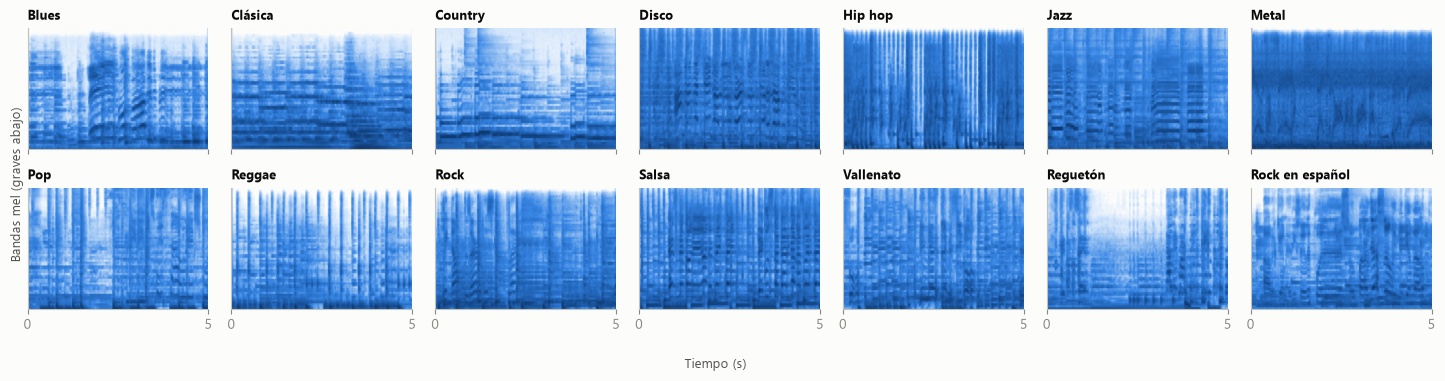

In [5]:
prueba = cat[cat["particion"] == "test"].sort_values("cancion")
ejemplos = {g: prueba[prueba["genero"] == g]["ruta"].iloc[0] for g in ESCENARIOS["C"]}
figuras.espectrogramas(ejemplos);

## La representación: MFCC por segmento

Cada canción se corta en segmentos de 5 s y de cada segmento se extraen 13 coeficientes MFCC por
ventana (216 ventanas por segmento). Los coeficientes resumen la envolvente del espectro, es decir,
el timbre. Los dos modelos reciben exactamente estos mismos segmentos.

In [6]:
por_cancion = mfcc.extraer(cat)
n_seg = pd.Series({c: len(x) for c, x in por_cancion.items()})
print(f"Forma de un segmento: {next(iter(por_cancion.values())).shape[1:]}")
print(f"Segmentos en total: {n_seg.sum()}; por canción: {n_seg.value_counts().sort_index().to_dict()}")

Forma de un segmento: (216, 13)
Segmentos en total: 7899; por canción: {5: 9, 6: 1309}


El perfil medio de cada género en entrenamiento, estandarizado por coeficiente, muestra qué tan
distintos son en promedio. Los nombres de las filas salen del propio catálogo, no de una lista
escrita a mano.

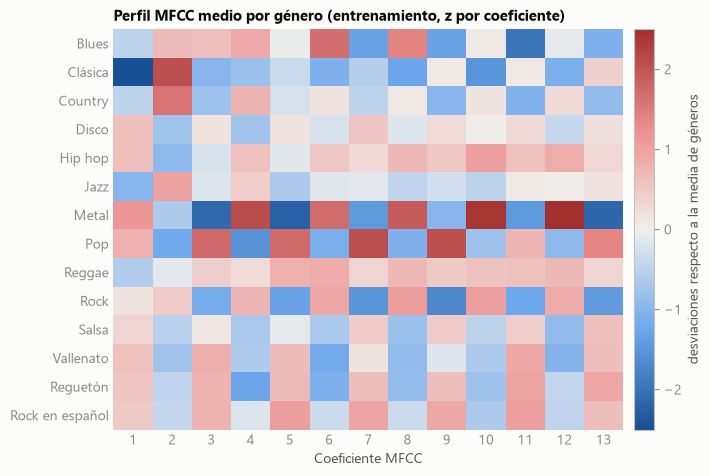

In [7]:
entrenamiento = cat[cat["particion"] == "train"]
perfil = pd.DataFrame({g: np.concatenate([por_cancion[c] for c in entrenamiento.loc[entrenamiento["genero"] == g, "cancion"]]).mean(axis=(0, 1))
                       for g in ESCENARIOS["C"]}).T
z = (perfil - perfil.mean()) / perfil.std()

from matplotlib.colors import LinearSegmentedColormap
divergente = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#ec8f8e", "#a32f2f"])
fig, ax = plt.subplots(figsize=(7, 5.2))
im = ax.imshow(z, cmap=divergente, vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_yticks(range(len(z)), [NOMBRES[g] for g in z.index])
ax.set_xticks(range(13), [f"{i}" for i in range(1, 14)])
ax.set_xlabel("Coeficiente MFCC")
ax.set_title("Perfil MFCC medio por género (entrenamiento, z por coeficiente)")
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="desviaciones respecto a la media de géneros");

El primer coeficiente sigue la energía global del segmento. Ordenados por él:

In [8]:
print(z[0].sort_values().rename(index=NOMBRES).round(2).to_string())

Clásica           -2.73
Jazz              -1.00
Reggae            -0.60
Country           -0.48
Blues             -0.48
Rock               0.14
Salsa              0.35
Rock en español    0.48
Reguetón           0.54
Vallenato          0.60
Hip hop            0.61
Disco              0.62
Pop                0.80
Metal              1.14


Clásica queda muy por debajo del resto y jazz también por debajo de la media; metal es el más alto,
seguido de pop, disco y hip hop.

¿A qué se parece, en promedio, el rock en español? La distancia entre perfiles medios lo ubica más
cerca del reguetón, la salsa y la disco que del rock de GTZAN, que a su vez queda junto al country y
el blues:

In [9]:
from scipy.spatial.distance import pdist, squareform
d = pd.DataFrame(squareform(pdist(z)), index=z.index, columns=z.index)
for g in ("rock_es", "rock"):
    cercanos = d.loc[g].drop(g).sort_values().head(3).rename(index=NOMBRES).round(2)
    print(f"Más cercanos a {NOMBRES[g]}: " + ", ".join(f"{k} ({v})" for k, v in cercanos.items()))

Más cercanos a Rock en español: Reguetón (1.55), Salsa (1.83), Disco (1.87)
Más cercanos a Rock: Country (2.72), Blues (2.9), Metal (3.6)


Es solo un promedio de timbre, pero anticipa algo: si los MFCC de las grabaciones de YouTube (más
recientes, con otra mezcla y masterización) se parecen entre sí por su producción, el modelo podría
separar el rock en español del rock de GTZAN por la fuente y no por el idioma. El cuaderno 04 lo
examina con los modelos entrenados.